# RM²–galaxy: Zhang & Lidz近似モデルとsimulationの比較

§3.2・式(3.3)の有限周期箱に対応した診断。元のgasは読まず、`coeval_projection_*.npz` の完成した2Dマップだけを使う。途中まで完成したsnapshotでも実行可能。追加の3D格子・キャッシュは作らない。

CMBを背景光源とする理想的なRMでも、銀河より後方まで積分する条件は同じ。CMB偏光から再構成したRMのtransfer function、noise、foreground、lensingはこの比較には含めない。CMBの最終散乱面までの完全なRMをTNGの低赤方偏移coneが再現するわけではない。

[論文](https://doi.org/10.1088/1475-7516/2026/07/096)の近似はsimulationで校正したモデルであり、厳密な独立理論予測ではない。


In [1]:
from pathlib import Path
import json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.cosmology import FlatLambdaCDM
from IPython.display import display


In [2]:
NOTEBOOK_DIR=Path.cwd()/'detect-mag' if (Path.cwd()/'detect-mag').is_dir() else Path.cwd()
CACHE_DIR=NOTEBOOK_DIR/'cache'
OUTPUT_DIR=NOTEBOOK_DIR/'fr_analytic_comparison'
BRIDGE_DIR=NOTEBOOK_DIR/'fr_coeval_to_lightcone'
LIGHTCONE_DIR=NOTEBOOK_DIR/'fr_basic_figures'
SELECTED_CACHE_FILES=[]  # optional explicit filenames; required if multiple caches exist for one snapshot
FIELD_METHOD='separate' # match the bridge analysis; 'direct' is a separate diagnostic
K_PAPER=3.0
GRID_N=500
BOX_H_CMPC=205.0
H=0.6774
N_BINS=28
CALIBRATION_Z_MAX=0.05  # fit K only at z~0, then keep it fixed at all other epochs
FIT_R_RANGE=(1.0,10.0) # h^-1 cMpc; descriptive fit, no covariance/significance claim
RUN_LIGHTCONE=True
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
assert FIELD_METHOD in ('separate','direct')
plt.rcParams.update({'figure.dpi':110,'font.size':11,'pdf.fonttype':42})
def savefig(fig,name):
    fig.savefig(OUTPUT_DIR/(name+'.png'),dpi=180,bbox_inches='tight')
    fig.savefig(OUTPUT_DIR/(name+'.pdf'),bbox_inches='tight')
    plt.show()
def digest(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(2**20),b''):h.update(b)
    return h.hexdigest()

def signed_axis(ax,scale,values):
    ax.set_yscale('symlog',linthresh=scale)
    vmax=float(np.nanmax(abs(np.asarray(values))))
    pmin=int(np.ceil(np.log10(scale)));pmax=int(np.floor(np.log10(max(vmax,scale))))
    positive=10.**np.arange(pmin,pmax+1,2)
    ax.set_yticks(np.r_[-positive[::-1],0.,positive])


## 有限箱で式(3.3)を評価する

$L$ は箱のcomoving長（Mpc）。保存済みのマップから
$$e_p=\langle n_{e,\rm com}\rangle_{\rm LOS}/\bar n_e-1,\qquad
R=W L\langle\widetilde B_z\rangle_{\rm LOS},\quad W=0.812\times10^6\bar n_e$$
と置く。離散周期箱では、LOS波数ゼロの面の積分をParsevalで評価できる：
$$I_B=\int\frac{d^2q}{(2\pi)^2}P_{\widetilde B}(q_\parallel=0,q_\perp)
=L\,\mathrm{Var}(\langle\widetilde B_z\rangle_{\rm LOS})
=\frac{\mathrm{Var}(R)}{W^2L}.$$
同じ面から評価した電子–tracerの投影相関は
$$w_{e,g}(r)=L\,\langle e_p(\boldsymbol x)\delta_{g,p}(\boldsymbol x+\boldsymbol r)\rangle.$$
よって式(3.3)の有限箱版は
$$w_{R^2,g}^{\rm model}(r)=2K\,\mathrm{Var}(R)\,\langle e_p\delta_{g,p}\rangle(r).$$

各snapshotの電子平均で整合的に規格化し、$W$は最終式で相殺される。ゼロFourier modeは除外。上式は同じ数値格子の全非ゼロ横方向modeを使い、円形Nyquist cutを別途入れない。

論文は3D等方平均した$P_{e,g}$と低波数への線形理論外挿も用いる。このnotebookは保存済み投影の$q_\parallel=0$面を使い、箱外スケールへ外挿しない。そのため論文のanalytic curveの完全な再現ではない。格子窓はsimulationとmodelの双方に残す。

有限箱ではRM平均が完全にゼロとは限らない。simulationの相関は元のR²で測定し、CSVには $2\langle R\rangle\langle Rg\rangle$ の寄与と、平均を引いてから二乗したRMの相関も記録する。両者の和が元の測定値になることを確認する。


In [3]:
def correlation_grid(field,count):
    field=np.asarray(field,float);count=np.asarray(count,float)
    if field.shape!=count.shape or not np.isfinite(field).all() or not np.isfinite(count).all():
        raise ValueError('Incompatible/nonfinite maps')
    if count.sum()<=0:raise ValueError('Empty tracer')
    a=field-field.mean();g=count/count.mean()-1
    return np.fft.ifft2(np.fft.fft2(a)*np.fft.fft2(g).conj()).real/field.size

def annulus_average(grid,edges,spacing):
    offset=np.fft.fftfreq(len(grid))*len(grid)*spacing
    xx,yy=np.meshgrid(offset,offset,indexing='ij');rr=np.hypot(xx,yy)
    rows=[]
    for lo,hi in zip(edges[:-1],edges[1:]):
        take=(rr>=lo)&(rr<hi)
        rows.append(dict(r_lo=lo,r_hi=hi,r=rr[take].mean() if take.any() else (lo+hi)/2,
                         w=grid[take].mean() if take.any() else np.nan,offsets=int(take.sum())))
    return pd.DataFrame(rows)

edges=np.geomspace(BOX_H_CMPC/GRID_N*.999,BOX_H_CMPC/2,N_BINS+1)
paths=[CACHE_DIR/name for name in SELECTED_CACHE_FILES] if SELECTED_CACHE_FILES else sorted(CACHE_DIR.glob('coeval_projection_*.npz'))
records=[];summaries=[];cache_sources=[];seen=set()
bridge_path=BRIDGE_DIR/'bridge_configuration.json'
bridge=json.loads(bridge_path.read_text()) if bridge_path.exists() else None
for path in paths:
    with np.load(path,allow_pickle=False) as f:
        p={k:f[k].copy() for k in f.files}
    if p['ne_projected'].shape!=(GRID_N,GRID_N):
        if SELECTED_CACHE_FILES:raise ValueError(f'Grid mismatch: {path}')
        continue
    snap=int(p['snap']);z=float(p['z'])
    if snap in seen:raise ValueError(f'Multiple caches for snapshot {snap}; set SELECTED_CACHE_FILES explicitly.')
    seen.add(snap)
    # Old NPZs do not embed gas/kernel metadata. Validate against bridge provenance if available.
    meta=bridge.get('coeval_metadata',{}).get(str(snap)) if bridge else None
    verified=bool(meta and path.name==f"coeval_projection_{hashlib.sha256(json.dumps(meta,sort_keys=True).encode()).hexdigest()[:20]}.npz")
    if verified:
        if meta['simulation']!='TNG300-3':raise ValueError('Unsupported simulation')
        if not np.isclose(bridge['box_h'],BOX_H_CMPC):raise ValueError('Box mismatch')
    else:warnings.warn(f'{path.name}: original selection/kernel metadata unverified; keep source settings with this comparison.')
    R=p['rm_'+FIELD_METHOD];e=p['ne_projected']/p['ne_projected'].mean()-1
    variance=float(np.var(R));L=BOX_H_CMPC/H;W=.812e6*float(p['ne_projected'].mean())
    bproj=(R-R.mean())/(W*L)
    # Independent spectral and real-space evaluations of the same magnetic integral.
    IB_spectral=L*float(np.sum(abs(np.fft.fft2(bproj))**2)/bproj.size**2)
    IB_real=variance/(W**2*L)
    assert np.isclose(IB_spectral,IB_real,rtol=1e-10,atol=0)
    for tracer in ('halo','galaxy'):
        count=p[tracer+'_count']
        if not count.sum():continue
        measured=annulus_average(correlation_grid(R**2,count),edges,BOX_H_CMPC/GRID_N)
        electron=annulus_average(correlation_grid(e,count),edges,BOX_H_CMPC/GRID_N)
        mean_term=annulus_average(correlation_grid(2*R.mean()*R,count),edges,BOX_H_CMPC/GRID_N)
        centered=annulus_average(correlation_grid((R-R.mean())**2,count),edges,BOX_H_CMPC/GRID_N)
        assert np.allclose(measured.w,centered.w+mean_term.w,rtol=1e-8,atol=max(variance,1e-30)*1e-10,equal_nan=True)
        measured['RM_mean_cross_term']=mean_term.w
        measured['centered_RM_squared_corr']=centered.w
        measured['electron_corr']=electron.w
        measured['base_model']=2*variance*electron.w  # K=1
        measured['model_K3']=K_PAPER*measured.base_model
        records.append(measured.assign(snap=snap,z=z,tracer=tracer))
    summaries.append(dict(snap=snap,z=z,RM_variance=variance,RM_mean=float(R.mean()),
                          ne_mean=float(p['ne_projected'].mean()),I_B_microG2_Mpc=IB_real,
                          metadata_verified=verified))
    cache_sources.append(dict(file=str(path.resolve()),sha256=digest(path),metadata_verified=verified))
if not records:raise FileNotFoundError('No compatible completed coeval projections; run the bridge through the desired snapshots first.')
result=pd.concat(records,ignore_index=True)
summary=pd.DataFrame(summaries).sort_values('z')
display(summary)


,snap,z,RM_variance,RM_mean,ne_mean,I_B_microG2_Mpc,metadata_verified
1,99,2.220446e-16,1.473293,-0.002360,2.085943e-07,0.169693,True
3,91,9.940180e-02,0.727697,0.000414,2.089012e-07,0.083570,True
9,84,1.972842e-01,0.786699,-0.002624,2.090479e-07,0.090219,True
7,78,2.977177e-01,0.718848,-0.001039,2.094038e-07,0.082157,True
6,72,3.999270e-01,0.660159,-0.000910,2.098314e-07,0.075143,True
8,67,5.030475e-01,0.635165,-0.001190,2.101838e-07,0.072055,True
5,59,7.001064e-01,0.341104,-0.000360,2.110063e-07,0.038395,True
10,50,9.972942e-01,0.165364,-0.000631,2.124980e-07,0.018353,True
11,40,1.495512e+00,0.057382,0.000056,2.141760e-07,0.006269,True
2,33,2.002028e+00,0.025539,-0.000350,2.159565e-07,0.002744,True


## K=3固定の比較と、z=0のみでの校正診断

RMの2点統計（分散）と電子–tracerの2点統計で、RM²–tracerという高次統計の形・振幅を説明できるかを検証する。RM²–tracer自体を入力にして予測したものではない。ただし入力の2点統計は同じsimulationから測定している。

Kのfitはz=0・1–10 h^-1 cMpcの単純最小二乗。誤差共分散を使わないため、統計的な推定値や有意度として解釈しない。高赤方偏移へKを移せるかを診断する。


,tracer,K_fixed,K_z0_diagnostic
0,galaxy,3.0,5.135504
1,halo,3.0,3.599631


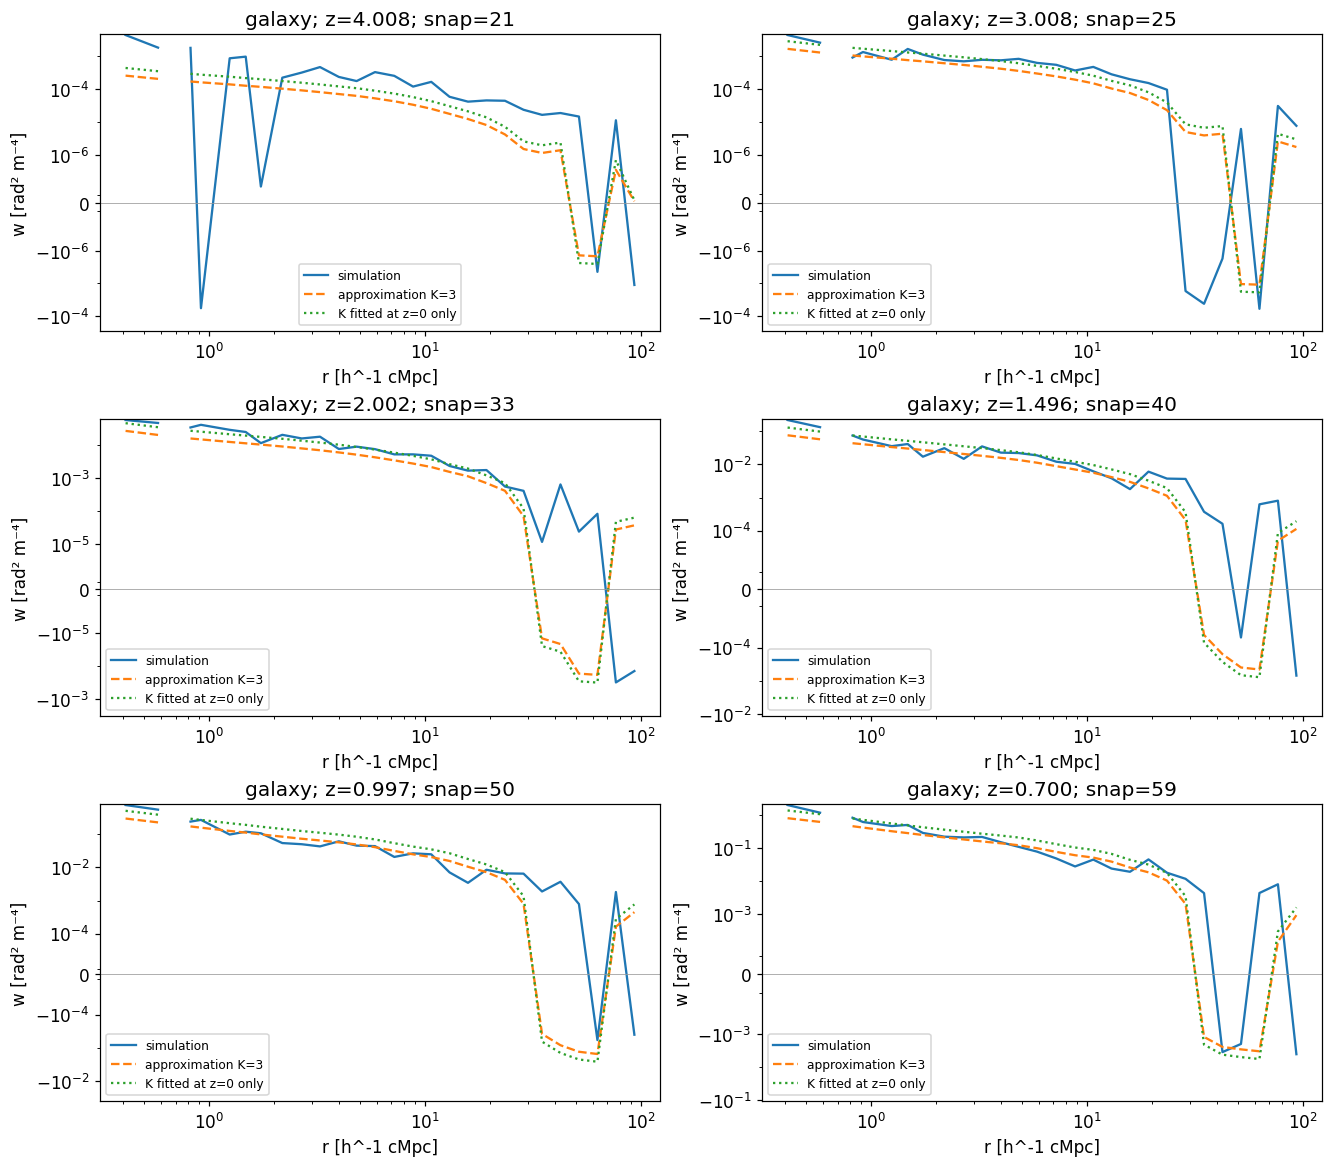

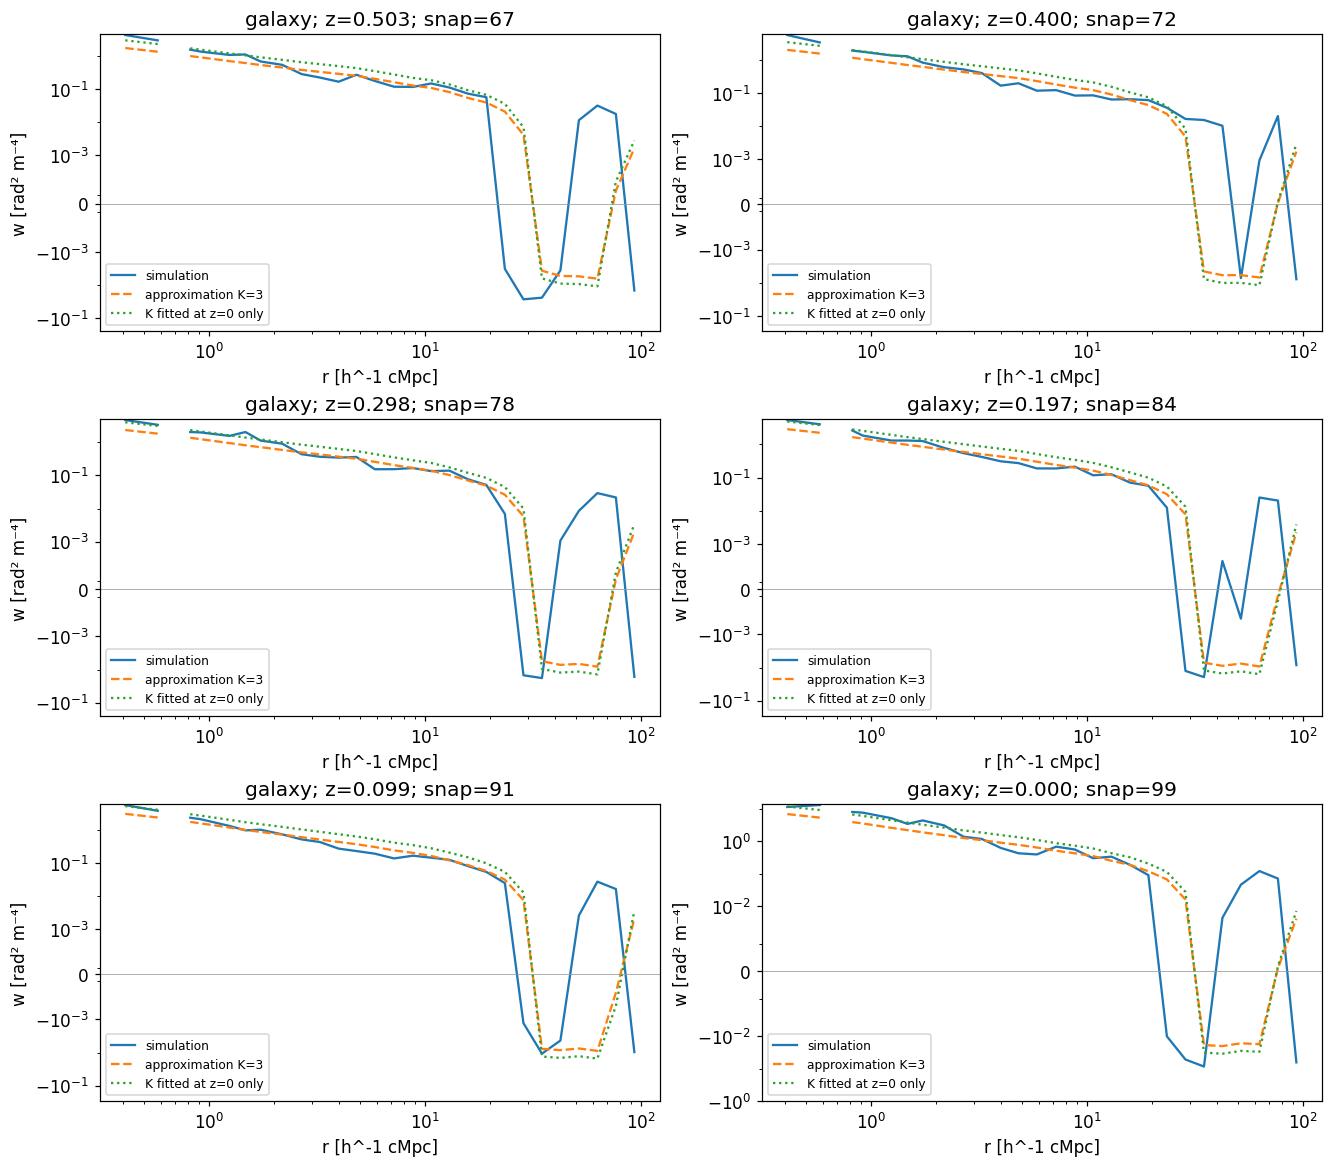

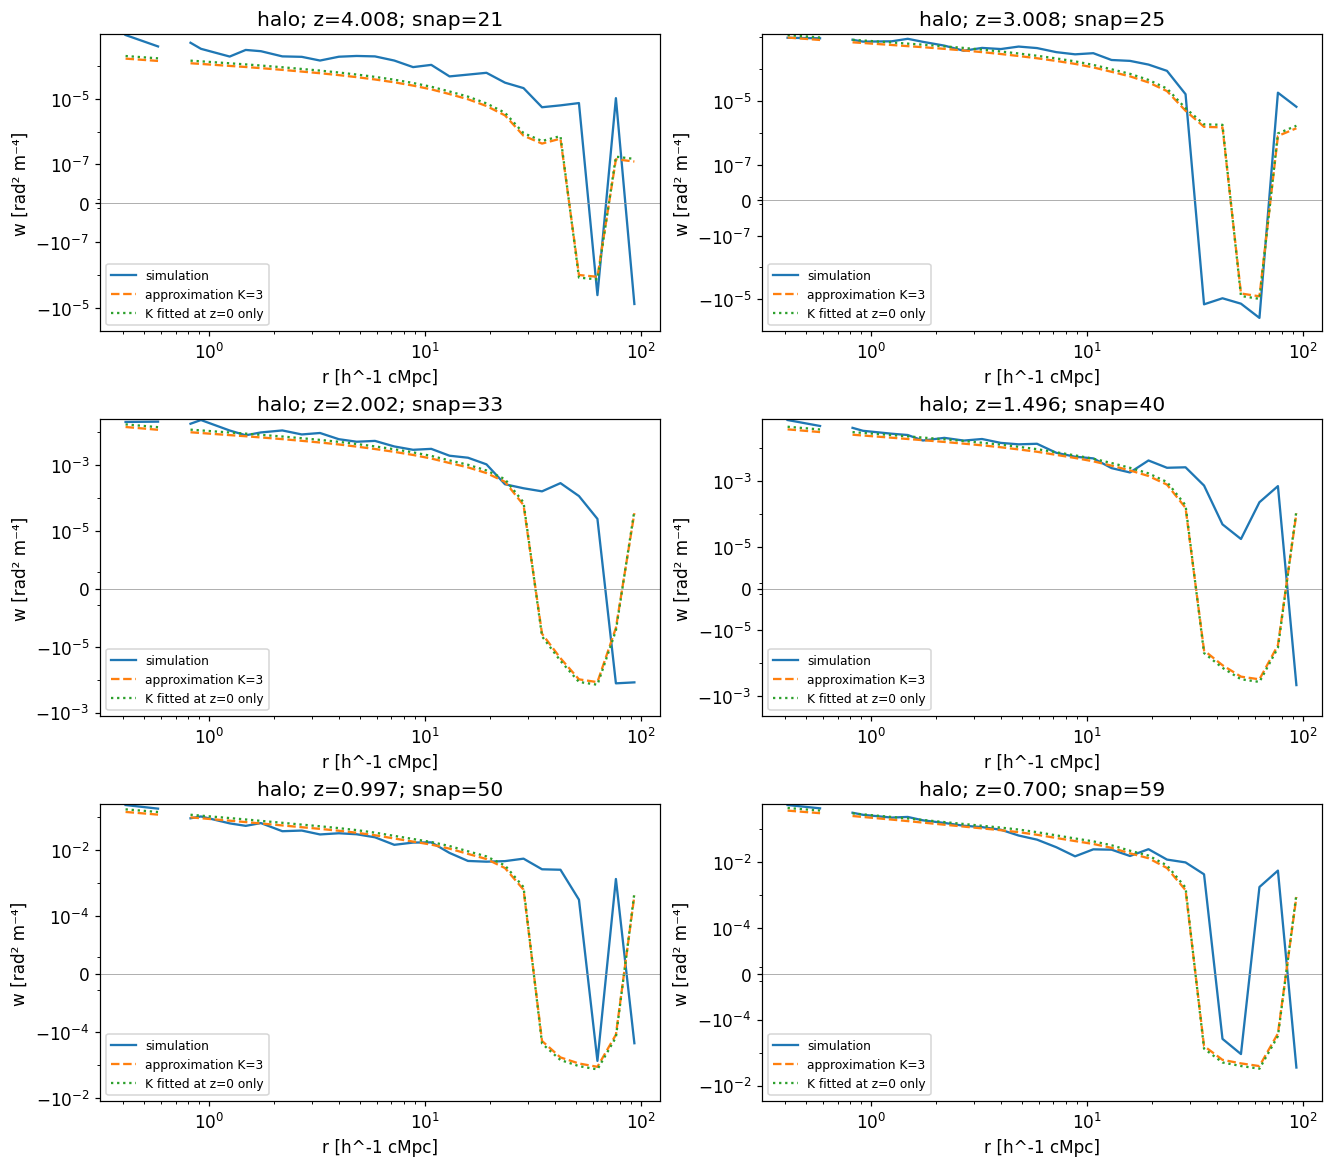

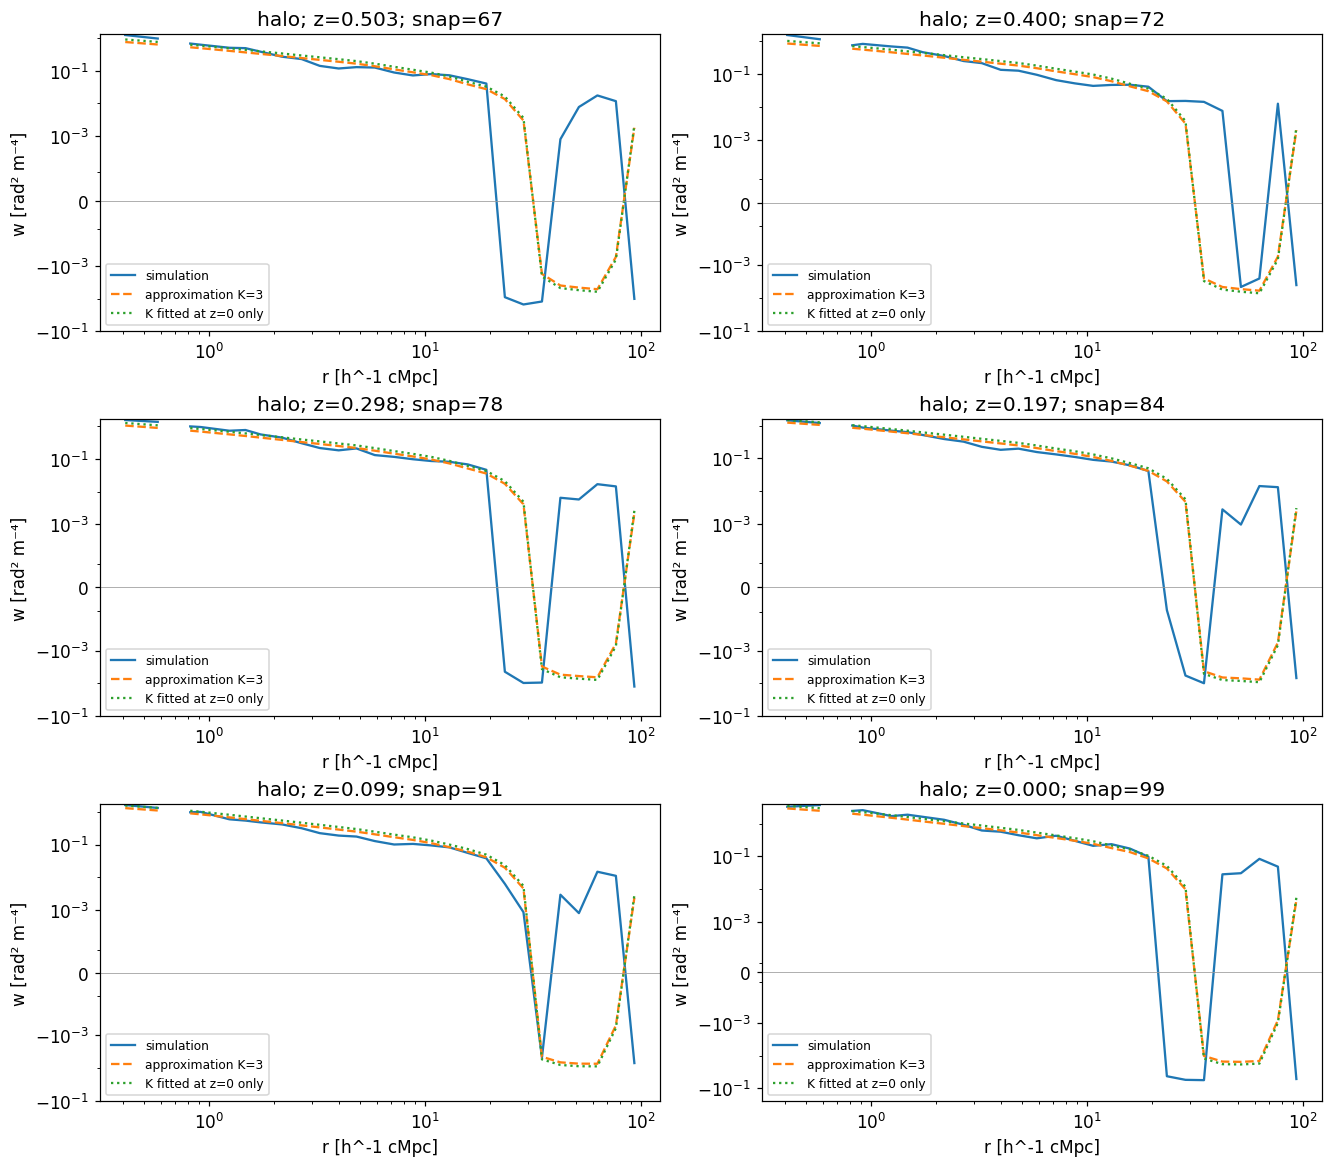

In [4]:
fit_values={}
for tracer in sorted(result.tracer.unique()):
    take=(result.tracer==tracer)&(result.z<=CALIBRATION_Z_MAX)&result.r.between(*FIT_R_RANGE)
    x=result.loc[take,'base_model'].to_numpy();y=result.loc[take,'w'].to_numpy()
    good=np.isfinite(x)&np.isfinite(y);x=x[good];y=y[good]
    fit_values[tracer]=float(x@y/(x@x)) if len(x) and x@x>0 else np.nan
result['K_z0_fit']=result.tracer.map(fit_values)
result['model_z0_calibrated']=result.base_model*result.K_z0_fit
result.to_csv(OUTPUT_DIR/'coeval_analytic_comparison.csv',index=False)
summary.to_csv(OUTPUT_DIR/'magnetic_amplitude_summary.csv',index=False)
display(pd.DataFrame([dict(tracer=t,K_fixed=K_PAPER,K_z0_diagnostic=k) for t,k in fit_values.items()]))
for tracer in sorted(result.tracer.unique()):
    groups=list(result[result.tracer==tracer].groupby('snap'))
    for start in range(0,len(groups),6):
        subset=groups[start:start+6]
        fig,axes=plt.subplots((len(subset)+1)//2,2,figsize=(12,3.5*((len(subset)+1)//2)),squeeze=False,constrained_layout=True)
        for ax,(snap,t) in zip(axes.ravel(),subset):
            ax.plot(t.r,t.w,label='simulation')
            ax.plot(t.r,t.model_K3,'--',label=f'approximation K={K_PAPER:g}')
            if np.isfinite(fit_values[tracer]):ax.plot(t.r,t.model_z0_calibrated,':',label='K fitted at z=0 only')
            scale=max(float(np.nanmax(abs(t[['w','model_K3']].to_numpy())))*1e-4,1e-30)
            ax.set(xscale='log',xlabel='r [h^-1 cMpc]',ylabel='w [rad² m⁻⁴]',title=f'{tracer}; z={t.z.iloc[0]:.3f}; snap={snap}')
            signed_axis(ax,scale,t[['w','model_K3']].to_numpy());ax.axhline(0,color='.6',lw=.5);ax.legend(fontsize=8)
        for ax in axes.ravel()[len(subset):]:ax.set_visible(False)
        savefig(fig,f'01_coeval_model_{tracer}_page_{start//6+1}')


## CMBを背景光源にしたlight coneへの接続（任意）

Limber近似では、真の銀河赤方偏移分布 $p_i(\chi)$ を用いて
$$w_i(\theta)\simeq\int d\chi\,p_i(\chi)\,w_{\rm coeval}(\chi\theta;z).$$
CMBでは光源側のcutoffを $\chi_*$ に置く。ここではTNG coneの銀河がすべてその手前にあるとして、galaxy catalogの等重み平均を64個のz小区間にまとめて評価する。photo-z選択なら、その選択後の真のz分布へ置き換える。

完成済みcoevalのz範囲外へ外挿せず、不足があればその銀河binはスキップする。snapshot間はzの線形補間、r方向も符号を保った線形補間。haloとgalaxyを混用せず、galaxyモデルのみ使う。

この比較は**窓補正前の参照モデル**。有限cone測定のintegral constraintや非Gaussian sample varianceは未モデル化。またcoevalとconeの格子・deposition定義が違い、Kを無条件で移せるとは仮定しない。coneの全経路RM²には層間項があり、Limberで小さい期待値でも個々の実現では残る。低zの磁場・高zの磁場が混在するCMBの長経路も、まずこの近似の成立を検証する対象である。


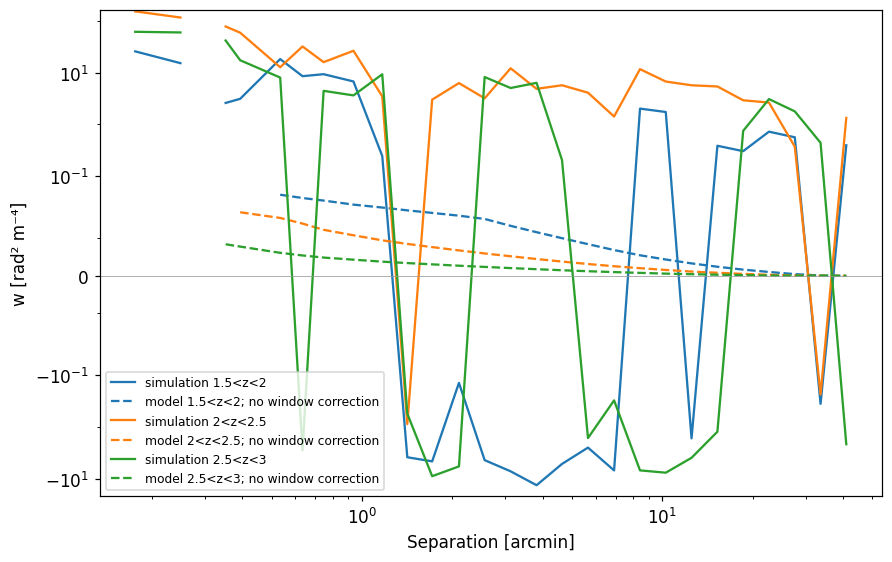

Outputs: /home/tnguser/tng-work/detect-mag/fr_analytic_comparison


In [5]:
cone_rows=[];cone_sources=[]
needed=[LIGHTCONE_DIR/'figure_configuration.json',LIGHTCONE_DIR/'theory_cone_galaxies.csv',BRIDGE_DIR/'lightcone_correlations.csv']
if RUN_LIGHTCONE and all(p.exists() for p in needed):
    cfg=json.loads(needed[0].read_text());mc=cfg['main_configuration']
    if cfg.get('rm_smoothing_arcmin')!=0:raise ValueError('Only unfiltered theoretical cone supported')
    if mc['SIMULATION']!='TNG300-3' or not np.isclose(float(mc['h']),H) or not np.isclose(float(mc['box_mpc'])*H,BOX_H_CMPC):
        raise ValueError('Cone cosmology/simulation mismatch')
    galaxies=pd.read_csv(needed[1]);measured=pd.read_csv(needed[2])
    cosmo=FlatLambdaCDM(H0=100*H,Om0=float(mc['omega_m']))
    tables=sorted([t.sort_values('r') for _,t in result[result.tracer=='galaxy'].groupby('snap')],key=lambda t:t.z.iloc[0])
    zs=np.array([t.z.iloc[0] for t in tables])
    if len(zs)<2:print('Lightcone skipped: at least two completed galaxy epochs are required.')
    else:
        fig,ax=plt.subplots(figsize=(8,5),constrained_layout=True)
        for (lo,hi),m in measured[measured.term=='total'].groupby(['z_lo','z_hi']):
            z=galaxies.loc[(galaxies.z_cos>=lo)&(galaxies.z_cos<hi),'z_cos'].to_numpy()
            if not len(z):continue
            if z.min()<zs.min() or z.max()>zs.max():
                print(f'Skipping {lo:g}<z<{hi:g}: completed coeval epochs do not bracket all selected galaxies.')
                continue
            bounds=np.linspace(lo,hi,65);j=np.clip(np.searchsorted(bounds,z,side='right')-1,0,63)
            theta=m.r.to_numpy()/60*np.pi/180;prediction=np.zeros_like(theta);valid=np.ones(len(theta),bool)
            for k in np.unique(j):
                selected=z[j==k];zc=float(selected.mean());weight=len(selected)/len(z)
                r=float(cosmo.comoving_distance(zc).value)*H*theta
                upper=int(np.searchsorted(zs,zc,side='right'));upper=min(max(upper,1),len(zs)-1);lower=upper-1
                f=(zc-zs[lower])/(zs[upper]-zs[lower])
                values=[]
                for idx in (lower,upper):
                    t=tables[idx];good=np.isfinite(t.model_K3)&np.isfinite(t.r)
                    values.append(np.interp(r,t.r[good],t.model_K3[good],left=np.nan,right=np.nan))
                value=(1-f)*values[0]+f*values[1]
                valid &= np.isfinite(value);prediction+=weight*np.nan_to_num(value)
            prediction[~valid]=np.nan
            out=m.copy();out['model_K3_no_window']=prediction;cone_rows.append(out)
            line=ax.plot(m.r,m.w,label=f'simulation {lo:g}<z<{hi:g}')[0]
            ax.plot(m.r,prediction,'--',color=line.get_color(),label=f'model {lo:g}<z<{hi:g}; no window correction')
        if cone_rows:
            cone_result=pd.concat(cone_rows,ignore_index=True)
            cone_result.to_csv(OUTPUT_DIR/'lightcone_analytic_reference.csv',index=False)
            scale=max(float(np.nanmax(abs(cone_result[['w','model_K3_no_window']].to_numpy())))*1e-4,1e-30)
            ax.set(xscale='log',xlabel='Separation [arcmin]',ylabel='w [rad² m⁻⁴]')
            signed_axis(ax,scale,cone_result[['w','model_K3_no_window']].to_numpy());ax.axhline(0,color='.6',lw=.5);ax.legend(fontsize=8)
            savefig(fig,'02_lightcone_model_reference')
        else:plt.close(fig)
    cone_sources=[dict(file=str(p.resolve()),sha256=digest(p)) for p in needed]
elif RUN_LIGHTCONE:print('Lightcone comparison skipped: required exports are not complete; coeval comparison remains available.')
provenance=dict(model='Zhang-Lidz Eq3.3 finite periodic box q_parallel=0 plane approximation',
                K_fixed=K_PAPER,K_z0_diagnostic=fit_values,field_method=FIELD_METHOD,
                grid_n=GRID_N,box_h=BOX_H_CMPC,h=H,zero_mode='excluded',
                low_k_extrapolation=False,observational_filter=False,CMB_RM_reconstruction=False,
                lightcone_window_correction=False,coeval_sources=cache_sources,cone_sources=cone_sources)
(OUTPUT_DIR/'analytic_configuration.json').write_text(json.dumps(provenance,indent=2,allow_nan=False) if all(np.isfinite(v) for v in fit_values.values()) else json.dumps({**provenance,'K_z0_diagnostic':{k:v if np.isfinite(v) else None for k,v in fit_values.items()}},indent=2))
print('Outputs:',OUTPUT_DIR.resolve())
